# Day 1-03｜課後演習：選手検出用のバウンディングボックスデータを作る

[Colab で開く](https://colab.research.google.com/github/henry753951/basketball-hackathon-course/blob/main/day1/d1_03_bbox_homework_ja.ipynb)

[English](d1_03_bbox_homework_en.ipynb) | [Japanese](d1_03_bbox_homework_ja.ipynb) | [Traditional Chinese](d1_03_bbox_homework.ipynb)


> この Notebook は **Day 2 で使うデータの準備**を目的とする。YOLO の推論全体は次の授業で扱う。  
> 少数の画像への矩形アノテーション、データセット版の公開、形式の確認を行い、Day 2 ではモデルの検出結果を読む。

## 学習目標

- 選手、ボール、リングなどのクラス名を統一する。
- 教材の少数の画像を Roboflow にアップロードし、アノテーションする。
- データセット版を公開し、YOLO detection 形式で取得してフォルダを確認する。
- 発展課題：教員のモデルで検証画像を 1 枚推論し、データの流れを確認する。

## 用語

- **バウンディングボックス（BBOX）**：左上と右下の座標で物体を囲む矩形。
- **クラス（Class）**：`player`、`ball` など、矩形内の物体の種類。
- **データセット版（Dataset version）**：その時点のアノテーションと分割を固定した再現可能なデータ。公開後に API で取得できる。
- **課後演習と Day 2 の役割**：今回はデータを作り、次回はモデルの出力を解釈する。


## 実行環境の確認

- Colab では **GPU** ランタイムを選ぶ。本教材の Ultralytics／PyTorch の設定では TPU を直接使用しない。
- CPU でも実行できるが、推論や動画の出力に時間がかかる。最初は `MAX_FRAMES` を小さくして処理を確認する。
- 実行前に各セルの目的を読み、出力が想定どおりか確認する。エラーが出ないことだけで正しいと判断しない。


## 演習の流れ：データの準備

1. 教材の 5 枚の画像を展開し、Roboflow にアップロードする。
2. 統一したクラス規則で矩形を描く。物体に沿わせつつ、身体の主要部分を切らない。
3. `Versions` でデータセット版を作成し、公開する。
4. Notebook で取得し、`data.yaml` と画像・ラベルの対応を確認する。
5. 発展課題としてモデルとデータの接続を確認する。信頼度や失敗例は Day 2 で詳しく扱う。

### 提出前の確認

- 少なくとも 5 枚の画像をアノテーションした。
- クラス名が教材の指定と一致している。
- 緩すぎる矩形、狭すぎる矩形、クラスの誤りが起こす問題を一つ説明できる。


In [1]:
import os
os.environ["BASKETBALL_COURSE_LANGUAGE"] = "ja"

# 教材フォルダを探し、必要なら取得して共通の環境設定を読み込みます。
# まず初期設定で実行し、出力を確認してから一度に一つのパラメータを変えます。
from pathlib import Path
import subprocess
import sys

DRIVE_MOUNTED = False
if "google.colab" in sys.modules:
    from google.colab import drive

    try:
        drive.mount("/content/drive")
        DRIVE_MOUNTED = True
    except NotImplementedError:
        print("この Colab ランタイムでは Drive をマウントできないため、ローカルの /content を使います。")

COURSE_ROOT_HINT = (
    Path("/content/drive/MyDrive/basketball_hackathon/course")
    if DRIVE_MOUNTED
    else next(
        (p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
         if (p / "src" / "course_setup.py").exists()),
        Path("/content/basketball_hackathon/course"),
    )
)
if not (COURSE_ROOT_HINT / "src" / "course_setup.py").exists() and "google.colab" in sys.modules:
    COURSE_ROOT_HINT.parent.mkdir(parents=True, exist_ok=True)
    subprocess.run([
        "git", "clone", "--depth", "1", "https://github.com/henry753951/basketball-hackathon-course.git", str(COURSE_ROOT_HINT)
    ], check=True)
if str(COURSE_ROOT_HINT) not in sys.path:
    sys.path.insert(0, str(COURSE_ROOT_HINT))

from src.course_setup import bootstrap_course_repo  # noqa: E402

COURSE_ROOT = bootstrap_course_repo(COURSE_ROOT_HINT, mount_drive=False)


教材ルート： /Users/henry753951/Developer/sandbox/basketball-hackathon-course
素材フォルダ： /Users/henry753951/Developer/sandbox/basketball-hackathon-course/assets
共通モジュール： /Users/henry753951/Developer/sandbox/basketball-hackathon-course/src


## Roboflow の YOLO detection 出力形式
Roboflow から YOLO 形式で出力したデータセット全体を、次の場所に配置する。

```text
assets/datasets/roboflow_bbox_yolo/
├── data.yaml
├── train/ または images/train + labels/train
├── valid/ または images/valid + labels/valid
└── test/  または images/test  + labels/test
```

検出クラスは参照プロジェクトと同じである：`ball`、`ball-in-basket`、`number`、`player`、`player-in-possession`、`player-jump-shot`、`player-layup-dunk`、`player-shot-block`、`referee`、`rim`。

Roboflow でアノテーションを修正した場合は、新しいデータセット版を公開してから、次の API ダウンロードを実行する。


In [2]:
# Roboflow の YOLO detection 出力形式を確認します。
# まず初期設定で実行し、出力を確認してから一度に一つのパラメータを変えます。
from getpass import getpass
from src.roboflow_utils import DETECTION_CLASSES, dataset_status, ensure_roboflow_detection_dataset

BBOX_DATASET_DIR = COURSE_ROOT / "assets" / "datasets" / "roboflow_bbox_yolo"
DETECTOR_MODEL_PATH = (
    COURSE_ROOT / "assets" / "models" / "detectors" / "yolo26n_basketball_player_best.pt"
)

# 課題の推奨手順：
# 1. assets/student_uploads/roboflow_bbox_student_upload_images.zip を展開します。
# 2. Roboflow の DATA > Upload Data で 5 枚をアップロードします。
# 3. DATA > Annotate の Unassigned で Annotate Images を選び、矩形を付けます。
# 4. Versions で Generate New Version / Publish を選びます。
# 5. 新しい workspace / project / version を下に入力します。
# 6. USE_ROBOFLOW_DOWNLOAD を True にします。
USE_ROBOFLOW_DOWNLOAD = False
ROBOFLOW_WORKSPACE = "YOUR_WORKSPACE"
ROBOFLOW_PROJECT = "YOUR_PROJECT"
ROBOFLOW_VERSION = 1
ROBOFLOW_API_KEY = ""
FORCE_DOWNLOAD = False

if USE_ROBOFLOW_DOWNLOAD:
    api_key = ROBOFLOW_API_KEY or getpass("Roboflow API key: ")
    data_yaml = ensure_roboflow_detection_dataset(
        BBOX_DATASET_DIR,
        workspace=ROBOFLOW_WORKSPACE,
        project=ROBOFLOW_PROJECT,
        version=ROBOFLOW_VERSION,
        api_key=api_key,
        export_format="yolov8",
        overwrite=FORCE_DOWNLOAD,
    )
    print("ready data.yaml:", data_yaml)

for i, name in enumerate(DETECTION_CLASSES):
    print(i, name)

print("\\ndataset status:")
print(dataset_status(BBOX_DATASET_DIR))
print("\\nmodel exists:", DETECTOR_MODEL_PATH.exists(), DETECTOR_MODEL_PATH)


0 ball
1 ball-in-basket
2 number
3 player
4 player-in-possession
5 player-jump-shot
6 player-layup-dunk
7 player-shot-block
8 referee
9 rim
\ndataset status:
{'path': '/Users/henry753951/Developer/sandbox/basketball-hackathon-course/assets/datasets/roboflow_bbox_yolo', 'exists': True, 'data_yaml': '/Users/henry753951/Developer/sandbox/basketball-hackathon-course/assets/datasets/roboflow_bbox_yolo/data.yaml', 'data_yaml_exists': False, 'splits': {}}
\nmodel exists: True /Users/henry753951/Developer/sandbox/basketball-hackathon-course/assets/models/detectors/yolo26n_basketball_player_best.pt


In [3]:
# Roboflow の YOLO detection 出力形式を確認します。
# まず初期設定で実行し、出力を確認してから一度に一つのパラメータを変えます。
RUN_TRAINING = False

if RUN_TRAINING:
    from ultralytics import YOLO

    data_yaml = BBOX_DATASET_DIR / "data.yaml"
    if not data_yaml.exists():
        raise FileNotFoundError(
            "data.yaml がありません。Roboflow の YOLO detection 出力を assets/datasets/roboflow_bbox_yolo/ に配置してください。"
        )

    model = YOLO("yolo26n.pt")
    results = model.train(
        data=str(data_yaml),
        epochs=50,
        imgsz=640,
        batch=0.8,
        workers=8,
        patience=30,
        close_mosaic=10,
        project=str(COURSE_ROOT / "assets" / "results" / "training" / "bbox_detection"),
        name="yolo26n_basketball_player",
        plots=True,
    )
    print(results)
else:
    print("RUN_TRAINING=False：assets/models/detectors/ の学習済み重みを使います。")


RUN_TRAINING=False：assets/models/detectors/ の学習済み重みを使います。


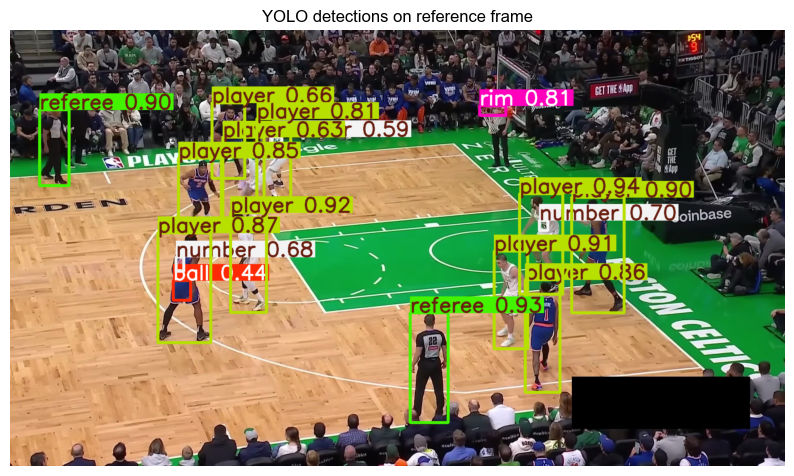

video: /Users/henry753951/Developer/sandbox/basketball-hackathon-course/assets/raw/reference_videos/boston-celtics-new-york-knicks-game-1-q1-01.54-01.48.mp4
detections: 17
saved: /Users/henry753951/Developer/sandbox/basketball-hackathon-course/assets/results/d1_03_yolo_detections.png


,frame_index,class_id,class_name,confidence,bbox_xyxy,track_id
0,15,3,player,0.936312,"[1262.3990478515625, 405.5212707519531, 1369.7...",None
1,15,8,referee,0.926773,"[991.1038818359375, 700.3985595703125, 1085.72...",None
2,15,3,player,0.922809,"[546.8359375, 452.7620849609375, 635.623779296...",None
3,15,3,player,0.910854,"[1199.2083740234375, 547.0396118164062, 1282.0...",None
4,15,3,player,0.898455,"[1391.52490234375, 414.43505859375, 1521.84143...",None


In [4]:
# Roboflow の YOLO detection 出力形式を確認します。
# まず初期設定で実行し、出力を確認してから一度に一つのパラメータを変えます。
import cv2
import pandas as pd
from ultralytics import YOLO

from src.cv_utils import save_image_rgb, save_json, show_image
from src.yolo_utils import detections_from_result

video_candidates = sorted((COURSE_ROOT / "assets" / "raw" / "reference_videos").glob("*.mp4"))
if not video_candidates:
    raise FileNotFoundError("参照動画がありません。assets/raw/reference_videos/ に mp4 を 1 本以上配置してください。")

video_path = video_candidates[0]
cap = cv2.VideoCapture(str(video_path))
if not cap.isOpened():
    raise FileNotFoundError(video_path)
cap.set(cv2.CAP_PROP_POS_FRAMES, 15)
ok, frame_bgr = cap.read()
cap.release()
if not ok:
    raise RuntimeError(f"フレーム 15 を読めません：{video_path}")
frame = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)

model = YOLO(str(DETECTOR_MODEL_PATH))
result = model.predict(frame, conf=0.25, imgsz=960, verbose=False)[0]
detections = detections_from_result(result, frame_index=15)
vis = result.plot().copy()
show_image(vis, "YOLO detections on reference frame")

out_image = COURSE_ROOT / "assets" / "results" / "d1_03_yolo_detections.png"
out_json = COURSE_ROOT / "assets" / "results" / "d1_03_yolo_detections.json"
save_image_rgb(out_image, vis)
save_json([record.__dict__ for record in detections], out_json)

print("video:", video_path)
print("detections:", len(detections))
print("saved:", out_image)
pd.DataFrame([record.__dict__ for record in detections]).head()


## 出力ファイル

- `assets/datasets/roboflow_bbox_yolo/data.yaml` と対応する images／labels：Roboflow の検出データ。
- `assets/results/d1_03_yolo_detections.png`：1 フレームの YOLO 検出確認図。
- `assets/results/d1_03_yolo_detections.json`：1 フレームの検出結果。
- `RUN_TRAINING=True` の場合は、Ultralytics の学習出力フォルダも作成される。
